# Tutorial: the full-shape $P_\ell(k)$ model and likelihood

This notebook goes through the redshift-space power spectrum model in `nbody_bias/` and the cobaya likelihood built on it,
using the **Abacus DR2 cutsky LRG1 mocks** ($0.4<z<0.6$, mean of 25 mocks) as data. By the end you will have

1. computed the model $P_0, P_2, P_4$ directly from the emulator and seen what each bias parameter does to them;
2. loaded the data vector, covariance and window matrix from the h5 likelihood package;
3. built the cobaya likelihood, evaluated it at a point, and recovered the best-fitting linear parameters;
4. fit the bias parameters to the data with cosmology held fixed.

**Requirements.** The `cobaya_jax` conda environment (cobaya, jax, `jaxeffort`, `jaxace`, `jaxmapse`, `classy`,
`desi_y3_cmb_data`), run from anywhere: the notebook finds the repo from its own location. Everything runs on a CPU:
the whole notebook takes about a minute, most of it spent compiling the model with JAX the first time it's called.

## 0. Setup

Two environment variables need setting **before** cobaya (and with it `mpi4py`) is imported. On Perlmutter, the Cray MPI
library otherwise aborts on a node without a CUDA-enabled jaxlib. Disabling the GPU device search silences a noisy warning.

In [1]:
import os, sys
os.environ['MPICH_GPU_SUPPORT_ENABLED'] = '0'   # Perlmutter: Cray MPI aborts at import without this
os.environ['JAX_PLATFORMS'] = 'cpu'

REPO = os.path.abspath('..')                    # this notebook lives in <repo>/notebooks
sys.path.insert(0, REPO)

import warnings
warnings.filterwarnings('ignore', category=FutureWarning, module='jax')  # dtype-promotion notices from the emulator code

import numpy as np
import matplotlib.pyplot as plt
import jax
jax.config.update('jax_enable_x64', True)

# The mock data: an h5 "likelihood package" with data vectors, covariances and window matrices for every tracer.
BASEDIR = os.path.join(REPO, 'data') + '/'    # copy of /pscratch/sd/g/gfarren/desi_y3_x_cmb_data/lklh_data_packages/ (see README)
DATFN = 'mock_abacus_cutsky_altmtl_phase_mean_qso_with_redshift_errors.h5'
TRACER = 'LRG1'

# AbacusSummit c000, the true cosmology of the mocks
TRUTH = dict(logA=3.03694, ns=0.9649, H0=67.36, omega_b=0.02237, omega_cdm=0.12, m_ncdm=0.06, w0=-1.0, wa=0.0)

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

## 1. The theory model

### 1.1 What the emulator computes

The model is one-loop Lagrangian perturbation theory (velocileptors LPT; `PT_model='EPT'` switches to the Eulerian version)
with the IR resummation, counterterms and stochastic terms of a standard EFT full-shape analysis. Because the galaxy power
spectrum is a **polynomial in the bias parameters**, the emulator does not return a single $P_\ell(k)$. It returns, for
each multipole, a **table of 19 columns**, one per bias monomial, so that

$$
P_\ell(k) \;=\; \sum_{i=1}^{19} c_i \, T_{\ell,i}(k), \qquad
c = \bigl(1,\; b_1,\; b_1^2,\; b_2,\; b_1 b_2,\; b_2^2,\; b_s,\; b_1 b_s,\; b_2 b_s,\; b_s^2,\; b_3,\; b_1 b_3,\;
\alpha_0,\; \alpha_2,\; \alpha_4,\; \alpha_6,\; \mathrm{SN}_0,\; \mathrm{SN}_2,\; \mathrm{SN}_4\bigr).
$$

The $b$'s are **Lagrangian** biases ($b_1^E = 1 + b_1$). The $\alpha$'s multiply $k^2 \mu^{2n} P_\mathrm{lin}$-type
counterterms. $\mathrm{SN}_0$ is the constant shot noise, and $\mathrm{SN}_2$, $\mathrm{SN}_4$ are the $k^2\mu^2$ and
$k^4\mu^4$ stochastic terms. Cosmology enters only through the tables, so changing a bias costs one dot product, and
changing cosmology costs one emulator call.

`compute_pkxi_emu` (in `nbody_bias/pkCodes_jax_emu.py`) wraps the emulators and applies, in order:

* **redshift-error damping** of $P(k,\mu)$: $1/(1 + a_2 (k\mu)^2 + a_4 (k\mu)^4)$; for LRGs $a_2=a_4=0$, so no damping;
* the **Alcock–Paczynski** distortion from the fiducial cosmology used to measure the data to the sampled one, through
  $q_\parallel = H^\mathrm{fid}(z)/H(z)$ and $q_\perp = \chi(z)/\chi^\mathrm{fid}(z)$, the same convention as the data.

All $k$ are in $h\,\mathrm{Mpc}^{-1}$ and all $P$ in $(h^{-1}\mathrm{Mpc})^3$.

### 1.2 Building the model for LRG1

The model needs the tracer's redshift and the fiducial distances. Redshifts are read from the data package rather than
typed in, so the model and the data can't disagree (the cutsky packages store the snapshot redshift of each mock, 0.5 for LRG1). Without the data package, the cell below
falls back to $z=0.5$, so all of section 1 still runs; sections 2-4 need the package.

In [2]:
from nbody_bias.fs_likelihood import read_zeffs, fiducial_cosmology
from nbody_bias.pkCodes_jax_emu import compute_pkxi_emu

if os.path.exists(BASEDIR + DATFN):
    zeffs = read_zeffs(BASEDIR + DATFN, [TRACER])
else:
    zeffs = [0.5]   # LRG1 snapshot redshift; change this if you change TRACER
    print(f'No data package at {BASEDIR + DATFN}: using z = {zeffs[0]}. Section 1 still runs, but sections 2-4 need the data.')
fid_dists, rd_fid, sig8_fids = fiducial_cosmology(zeffs)
print(f'{TRACER}: z = {zeffs[0]}, fiducial H(z) = {float(fid_dists[0, 0]):.2f} km/s/(Mpc/h), '
      f'chi(z) = {float(fid_dists[0, 1]):.1f} Mpc/h, sigma8_fid(z) = {sig8_fids[0]:.4f}')

emu = compute_pkxi_emu(zeffs=jax.numpy.array(zeffs), PT_model='LPT', fid_dists=fid_dists, rd_fid=rd_fid)
pell_tables = jax.jit(emu.compute_zerr_damped_pell_tables, static_argnames=('damp_stoch', 'pdf_damp', 'res_damp'))

LRG1: z = 0.5, fiducial H(z) = 132.24 km/s/(Mpc/h), chi(z) = 1315.1 Mpc/h, sigma8_fid(z) = 0.6213


The emulator takes the cosmology as the vector $(\ln 10^{10}A_s,\ n_s,\ H_0,\ \omega_b,\ \omega_\mathrm{cdm},\ M_\nu,\ w_0,\ w_a)$,
with the damping parameters $(a_2, a_4)$ appended, and the index of the redshift. The first call compiles the function
(a few seconds); after that a call takes milliseconds.

In [3]:
import time

def cosmo_vector(c, a2=0., a4=0.):
    return jax.numpy.array([c['logA'], c['ns'], c['H0'], c['omega_b'], c['omega_cdm'], c['m_ncdm'], c['w0'], c['wa'], a2, a4])

t0 = time.time()
k, T0, T2, T4 = [np.asarray(x) for x in pell_tables(cosmo_vector(TRUTH), 0, damp_stoch=True)]
print(f'first call (compiles): {time.time() - t0:.1f} s')
t0 = time.time()
pell_tables(cosmo_vector(TRUTH), 0, damp_stoch=True)[1].block_until_ready()
print(f'second call: {1e3 * (time.time() - t0):.1f} ms')
print(f'k: {len(k)} points from {k[0]:.4f} to {k[-1]:.3f} h/Mpc; each table has shape {T0.shape} (k, monomial)')

first call (compiles): 4.5 s
second call: 5.6 ms
k: 59 points from 0.0005 to 0.500 h/Mpc; each table has shape (59, 19) (k, monomial)


### 1.3 From tables to $P_\ell(k)$

Contracting the tables with the monomial vector gives the model. The function below does that (it's the same
contraction as `JointLikelihood.combine_bias_terms_pkell`). As a first guess, take $b_1 = 0.8$ (Eulerian bias
$1 + b_1 = 1.8$, typical of LRGs at $z\sim0.5$) and everything else zero.

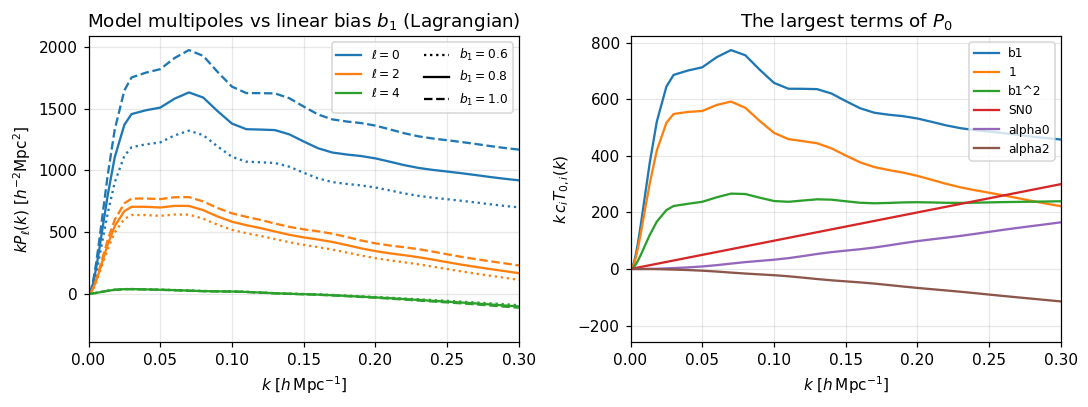

In [4]:
def monomials(b1=0., b2=0., bs=0., b3=0., alpha0=0., alpha2=0., alpha4=0., alpha6=0., sn0=0., sn2=0., sn4=0.):
    return np.array([1, b1, b1**2, b2, b1 * b2, b2**2, bs, b1 * bs, b2 * bs, bs**2, b3, b1 * b3,
                     alpha0, alpha2, alpha4, alpha6, sn0, sn2, sn4])

def pells(tables, **bias):
    c = monomials(**bias)
    return [T @ c for T in tables]

fiducial_bias = dict(b1=0.8)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for b1, ls in [(0.6, ':'), (0.8, '-'), (1.0, '--')]:
    P0, P2, P4 = pells((T0, T2, T4), **{**fiducial_bias, 'b1': b1})
    for P, col, ell in [(P0, 'C0', 0), (P2, 'C1', 2), (P4, 'C2', 4)]:
        ax[0].plot(k, k * P, color=col, ls=ls, label=rf'$\ell={ell}$' if b1 == 0.8 else None)
for b1, ls in [(0.6, ':'), (0.8, '-'), (1.0, '--')]:
    ax[0].plot([], [], 'k', ls=ls, label=f'$b_1 = {b1}$')
ax[0].set(xlabel=r'$k\ [h\,\mathrm{Mpc}^{-1}]$', ylabel=r'$k P_\ell(k)\ [h^{-2}\mathrm{Mpc}^2]$', xlim=(0, 0.3),
          title=r'Model multipoles vs linear bias $b_1$ (Lagrangian)')
ax[0].legend(ncol=2, fontsize=8)

# which monomials matter: each column's contribution to P0, with illustrative nonzero nuisance values
c = monomials(**fiducial_bias, b2=0.4, bs=0.5, alpha0=10., alpha2=-20., sn0=1000.)
names = ['1', 'b1', 'b1^2', 'b2', 'b1 b2', 'b2^2', 'bs', 'b1 bs', 'b2 bs', 'bs^2', 'b3', 'b1 b3',
         'alpha0', 'alpha2', 'alpha4', 'alpha6', 'SN0', 'SN2', 'SN4']
for i in np.argsort(-np.abs(c[:, None] * T0.T).max(axis=1))[:6]:
    ax[1].plot(k, k * c[i] * T0[:, i], label=names[i])
ax[1].set(xlabel=r'$k\ [h\,\mathrm{Mpc}^{-1}]$', ylabel=r'$k\, c_i T_{0,i}(k)$', xlim=(0, 0.3),
          title=r'The largest terms of $P_0$')
ax[1].legend(fontsize=8)
plt.tight_layout()

On the left, $b_1$ mostly rescales $P_0$ and, less, $P_2$: the Kaiser effect. On the right, the terms in $1$, $b_1$ and
$b_1^2$ dominate; the counterterm and shot-noise terms are corrections that grow with $k$. The next cell shows how each of the other parameters changes the multipoles,
as the change in $kP_\ell$ when that parameter is raised by the step shown.

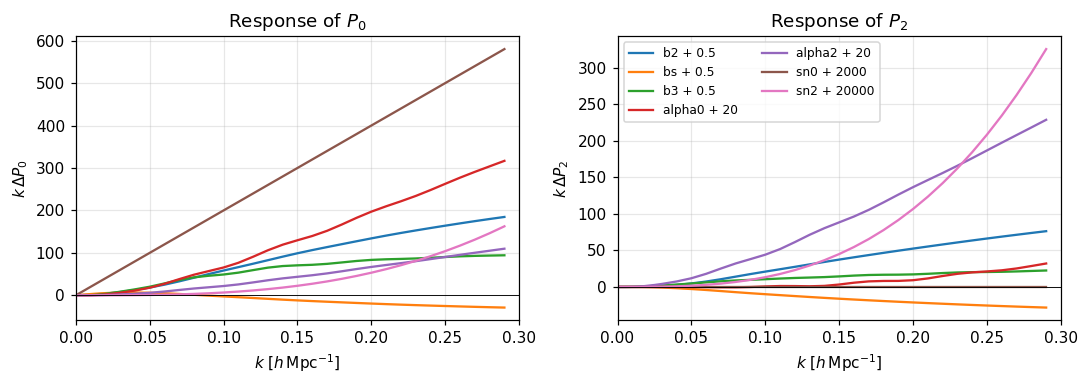

In [5]:
steps = dict(b2=0.5, bs=0.5, b3=0.5, alpha0=20., alpha2=20., sn0=2000., sn2=2e4)
kmax_plot = k <= 0.3
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), sharex=True)
P_ref = pells((T0, T2, T4), **fiducial_bias)
for name, step in steps.items():
    P_new = pells((T0, T2, T4), **{**fiducial_bias, name: fiducial_bias.get(name, 0.) + step})
    for a, ell in zip(axs, (0, 1)):
        a.plot(k[kmax_plot], (k * (P_new[ell] - P_ref[ell]))[kmax_plot], label=f'{name} + {step:g}')
for a, ell in zip(axs, (0, 2)):
    a.axhline(0, color='k', lw=0.6)
    a.set(xlabel=r'$k\ [h\,\mathrm{Mpc}^{-1}]$', ylabel=rf'$k\,\Delta P_{ell}$', xlim=(0, 0.3), title=rf'Response of $P_{ell}$')
axs[1].legend(fontsize=8, ncol=2)
plt.tight_layout()

$\alpha_0, \alpha_2, \mathrm{SN}_0, \mathrm{SN}_2$ (and $\alpha_4$, $\mathrm{SN}_4$) enter the model **linearly**,
so the likelihood marginalizes them analytically (section 3). Only $b_1, b_2, b_s$ (and $b_3$, usually fixed
to 0) are nonlinear and have to be sampled or minimized.

## 2. The data

### 2.1 What's in the likelihood package

`desi_y3_cmb_data.LikelihoodPackage` reads one h5 file holding every tracer's measurements. We request LRG1's
power spectrum (`p3d`) with the baseline scale cuts: $P_0$ and $P_2$ from $0.02$ to $0.2\,h\,\mathrm{Mpc}^{-1}$,
rebinned to $\Delta k = 0.005\,h\,\mathrm{Mpc}^{-1}$. The package applies the cuts to the data vector, covariance
and window consistently.

In [6]:
from desi_y3_cmb_data import LikelihoodPackage, ProductRequest, ScaleCuts

cuts = ScaleCuts(k_min={f'{TRACER}/P0': 0.02, f'{TRACER}/P2': 0.02},
                 k_max={f'{TRACER}/P0': 0.2, f'{TRACER}/P2': 0.2},
                 delta_k=0.005, multipoles=(0, 2))
with LikelihoodPackage(BASEDIR + DATFN) as pkg:
    inputs = pkg.build_likelihood_inputs([ProductRequest(sample=TRACER, observable='p3d')], scale_cuts=cuts)

p3d = inputs['products'][0]
kdat = p3d['bins']['by_multipole']['P0']['k_eff']           # same k bins for P0 and P2
data = inputs['data_vector'].reshape(2, -1)                   # (P0, P2)
err = np.sqrt(np.diag(inputs['covariance'])).reshape(2, -1)
W = p3d['window']
ktheory = p3d['theory_bins']['k_eff']

print(f"data vector: {inputs['data_vector'].shape} = P0, P2 at {len(kdat)} k bins ({kdat[0]:.4f}-{kdat[-1]:.4f} h/Mpc)")
print(f"covariance: {inputs['covariance'].shape}, source: {inputs['covariance_source']}")
print(f"window: {W.shape} = (data bins) x (theory P0, P2, P4 on {len(ktheory)} k points, {ktheory[0]:.4f}-{ktheory[-1]:.4f})")
print('additive templates:', list(p3d['additive_templates']['names']) if p3d['additive_templates'] else None)

data vector: (72,) = P0, P2 at 36 k bins (0.0225-0.1975 h/Mpc)
covariance: (72, 72), source: analytic
window: (72, 1503) = (data bins) x (theory P0, P2, P4 on 501 k points, 0.0005-0.5005)
additive templates: ['angular_upweighting_data_difference']


Three things to notice:

* **The window matrix** maps the theory $P_0, P_2, P_4$, evaluated on a fine $k$ grid, to the measured bins. It encodes
  the survey geometry (mode coupling, and $P_4$ leaking into the measured $P_0$ and $P_2$). The model always goes
  through it; never compare unwindowed theory to the data.
* **The AUW template** (`angular_upweighting_data_difference`) is the difference between spectra measured with and without
  angular upweighting of fiber-assigned pairs, a systematic correction. The likelihood adds it to the model with a free
  amplitude (prior $\mathcal{N}(0, 0.3)$), marginalized analytically like the counterterms.
* The covariance is analytic and corresponds to the volume of **one** mock, while the data are the mean of 25. The
  error bars are therefore those of a single DESI-like realization; the mean itself is much less noisy.

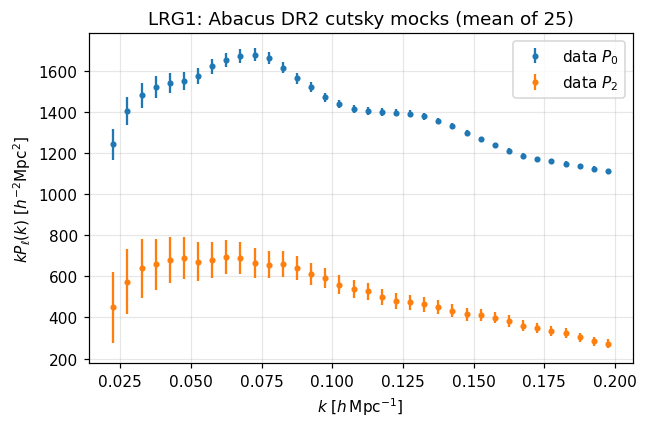

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
for i, (ell, col) in enumerate([(0, 'C0'), (2, 'C1')]):
    ax.errorbar(kdat, kdat * data[i], kdat * err[i], fmt='o', ms=3, color=col, label=rf'data $P_{ell}$')
ax.set(xlabel=r'$k\ [h\,\mathrm{Mpc}^{-1}]$', ylabel=r'$k P_\ell(k)\ [h^{-2}\mathrm{Mpc}^2]$',
       title=f'{TRACER}: Abacus DR2 cutsky mocks (mean of 25)')
ax.legend()
plt.tight_layout()

### 2.2 Putting the model through the window

To compare with the data, interpolate the model onto the window's theory grid, stack $(P_0, P_2, P_4)$ and multiply
by $W$. This is exactly what `JointLikelihood.fs_observe` does. The biases are still the first guess from section 1,
with no counterterms or shot noise, so don't expect a good match yet; section 4 fits them.

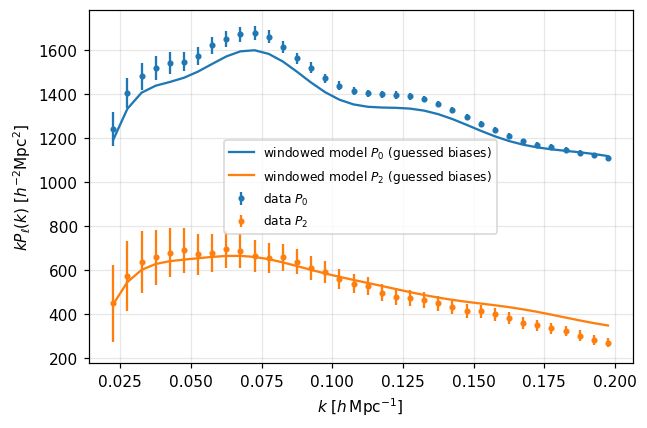

In [8]:
from scipy.interpolate import InterpolatedUnivariateSpline as Spline

def windowed(k, P_ells):
    # anchor P=0 at k=0 so the spline behaves on the window's lowest k points, as in fs_predict
    stacked = np.concatenate([Spline(np.append(0., k), np.append(0., P), ext=3)(ktheory) for P in P_ells])
    return (W @ stacked).reshape(2, -1)

model_guess = windowed(k, pells((T0, T2, T4), **fiducial_bias))
fig, ax = plt.subplots(figsize=(6, 4))
for i, (ell, col) in enumerate([(0, 'C0'), (2, 'C1')]):
    ax.errorbar(kdat, kdat * data[i], kdat * err[i], fmt='o', ms=3, color=col, label=rf'data $P_{ell}$')
    ax.plot(kdat, kdat * model_guess[i], color=col, label=rf'windowed model $P_{ell}$ (guessed biases)')
ax.set(xlabel=r'$k\ [h\,\mathrm{Mpc}^{-1}]$', ylabel=r'$k P_\ell(k)\ [h^{-2}\mathrm{Mpc}^2]$')
ax.legend(fontsize=8)
plt.tight_layout()

## 3. The cobaya likelihood

### 3.1 Two components

`nbody_bias/fs_likelihood.py` packages the steps above as two cobaya components:

* **`pk_theory_zs`** (a cobaya `Theory`) takes the cosmological parameters and the damping parameters `a2_<tracer>`, `a4_<tracer>`,
  and provides the monomial tables at each tracer's redshift (`taylor_pk_ell_mod`). It also provides
  `zPars` $= [\sigma_8(z)/\sigma_8^\mathrm{fid}(z),\ f(z),\ q_\parallel,\ q_\perp]$ and the derived parameters
  $\sigma_8$ and $\Omega_m$.
* **`JointLikelihood`** (a cobaya `Likelihood`) loads the data as in section 2, builds the windowed model, and
  analytically marginalizes the linear parameters.

### 3.2 The bias parameterization

The sampled bias parameters are **not** the Lagrangian $b$'s of section 1. With `bsig8: 1` and `AP_scale: true` they are

$$
\texttt{bsig8} = (1 + b_1)\,\frac{\sigma_8(z)}{\sigma_8^\mathrm{fid}(z)}\,\sqrt{A_\mathrm{AP}}, \qquad
\texttt{b2sig8} = b_2 \left(\frac{\sigma_8(z)}{\sigma_8^\mathrm{fid}(z)}\right)^{2}\sqrt{A_\mathrm{AP}}, \qquad
A_\mathrm{AP} = \frac{1}{q_\parallel q_\perp^2},
$$

and likewise `bssig8` ($\sigma_8^2$) and `b3sig8` ($\sigma_8^3$). These combinations are what the data constrain directly,
so they are nearly uncorrelated with cosmology; that makes sampling much more efficient. With `ct_reparam: true`, the
counterterm parameters are rescaled the same way: $\alpha_0 = (1+b_1)^2\tilde\alpha_0$,
$\alpha_2 = f(1+b_1)(\tilde\alpha_0 + \tilde\alpha_2)$, and so on, where the $\tilde\alpha$ are the parameters in the
priors file.

### 3.3 Analytic marginalization of the linear parameters

Write the model as $m(\theta) = m_0 + \sum_a \theta_a t_a$, where the $\theta_a$ are the linear parameters
($\tilde\alpha_0, \tilde\alpha_2, \mathrm{SN}_0, \mathrm{SN}_2$, AUW amplitude) with Gaussian priors $\mathcal{N}(\mu_a, \sigma_a)$,
and $t_a$ is the change in the windowed model for a unit change in $\theta_a$ (computed by finite differences, which
is exact here). The integral over $\theta$ is Gaussian:

$$
\ln \mathcal{L}_\mathrm{marg} = -\tfrac12 \Delta^T C^{-1} \Delta + \tfrac12 V^T L^{-1} V - \tfrac12 \ln\det L + \tfrac{N_\mathrm{lin}}{2}\ln 2\pi,
\qquad \Delta = d - m(\mu),\quad V_a = t_a^T C^{-1}\Delta,\quad L_{ab} = t_a^T C^{-1} t_b + \delta_{ab}/\sigma_a^2 .
$$

The best-fit linear parameters are $\hat\theta = \mu + L^{-1}V$. Two flags control which terms are kept:

| flag | meaning |
|---|---|
| `include_priors: true` | include the $1/\sigma_a^2$ prior term in $L$ (keep this on) |
| `optimize: false` | include the $-\tfrac12\ln\det L$ volume term: the right choice for **sampling** the marginal posterior |
| `optimize: true` | drop it: then $\ln\mathcal{L}$ is the likelihood **maximized** over the linear parameters (a profile), the right choice for **minimizing** |

The priors on the linear parameters come from `configs/params_linear_LRG1.yaml`.

### 3.4 Building the model

A cobaya model is defined by a dictionary (or the equivalent yaml; see `configs/fit_LRG1_abacus_cutsky.yaml`).
Cosmological parameters given as plain numbers are **fixed**; ones with a `prior` are free. Here all of cosmology
is fixed to the truth, and the three nonlinear biases are free with the baseline priors.

In [9]:
from cobaya.model import get_model

def make_info(optimize=False):
    return {
        'theory': {
            'nbody_bias.fs_likelihood.pk_theory_zs': {
                'fs_sample_names': [TRACER], 'PT_model': 'LPT', 'basedir': BASEDIR, 'datfn': DATFN},
        },
        'likelihood': {
            f'DESI_RSD_{TRACER}': {
                'class': 'nbody_bias.fs_likelihood.JointLikelihood',
                'basedir': BASEDIR, 'datfn': DATFN, 'fs_sample_names': [TRACER],
                'linear_param_dict_fn': os.path.join(REPO, f'configs/params_linear_{TRACER}.yaml'),
                'auw_prior': [0.0, 0.3],
                # scale cuts: P0 and P2 from 0.02 to 0.2 h/Mpc, rebinned to dk = 0.005; no hexadecapole
                'fs_kmins': [0.02], 'fs_qmins': [0.02], 'fs_mmaxs': [0.2], 'fs_qmaxs': [0.2], 'fs_hmaxs': [0.0],
                'delta_k': 0.005, 'hexa': False,
                'include_priors': True, 'optimize': optimize, 'jeff': False,
                'cov_fac': [1.0], 'invcov_fac': [1.0],
                'bsig8': 1.0, 'ct_reparam': True, 'AP_scale': True,
            },
        },
        'params': {
            # cosmology: fixed to the truth of the mocks
            **TRUTH,
            'sigma8': {'latex': r'\sigma_8'}, 'omegam': {'latex': r'\Omega_m'},   # derived
            # nonlinear biases: free
            # 'ref' is where samplers and minimizers start: a distribution around a reasonable guess
            f'bsig8_{TRACER}': {'prior': {'min': 0.1, 'max': 3.0}, 'ref': {'dist': 'norm', 'loc': 1.8, 'scale': 0.1}},
            f'b2sig8_{TRACER}': {'prior': {'dist': 'norm', 'loc': 0.0, 'scale': 10}, 'ref': {'dist': 'norm', 'loc': 0.0, 'scale': 0.5}},
            f'bssig8_{TRACER}': {'prior': {'dist': 'norm', 'loc': 0.0, 'scale': 10}, 'ref': {'dist': 'norm', 'loc': 0.0, 'scale': 0.5}},
            f'b3sig8_{TRACER}': 0.0,
            # no redshift-error damping for LRGs
            f'a2_{TRACER}': 0.0, f'a4_{TRACER}': 0.0,
        },
    }

model = get_model(make_info())
print('sampled parameters:', list(model.parameterization.sampled_params()))

pk_theory_zs zfids from mock_abacus_cutsky_altmtl_phase_mean_qso_with_redshift_errors.h5: {'LRG1': 0.5}
zfids from mock_abacus_cutsky_altmtl_phase_mean_qso_with_redshift_errors.h5: {'LRG1': 0.5}
Loaded data!
Adding auw_LRG1 ~ N(0.0, 0.3)


sampled parameters: ['bsig8_LRG1', 'b2sig8_LRG1', 'bssig8_LRG1']


### 3.5 Evaluating the likelihood at a point

`model.logposterior(point)` returns the log-prior, log-likelihood and derived parameters at a point given as a
dictionary of the sampled parameters. We use the same first guess as in section 1. At the true cosmology the
$\sigma_8$ and AP factors are almost exactly 1, so $b_1 = 0.8$ becomes `bsig8` $= 1.8$.

In [10]:
point = {f'bsig8_{TRACER}': 1.8, f'b2sig8_{TRACER}': 0.0, f'bssig8_{TRACER}': 0.0}

t0 = time.time()
res = model.logposterior(point)
print(f'(took {time.time() - t0:.1f} s)')
print(f'log-likelihood {res.loglike:.3f}   log-prior {res.logprior:.3f}   log-posterior {res.logpost:.3f}')
print('derived:', dict(zip(model.parameterization.derived_params(), np.round(res.derived, 5))))
t0 = time.time()
model.logposterior({**point, f'b2sig8_{TRACER}': 0.0})
print(f'a second evaluation (new bias, same cosmology) took {1e3 * (time.time() - t0):.1f} ms: cobaya caches the theory '
      'tables, so only the bias contraction and the marginalization are redone')

(took 4.4 s)
log-likelihood 13.503   log-prior -7.508   log-posterior 5.995
derived: {'sigma8': np.float64(0.80767), 'omegam': np.float64(0.31519)}
a second evaluation (new bias, same cosmology) took 0.3 ms: cobaya caches the theory tables, so only the bias contraction and the marginalization are redone


### 3.6 Looking inside: the best-fit linear parameters and the model

After an evaluation, the likelihood object holds the pieces of the marginalization. `get_best_fit()` returns the
windowed model at the best-fit linear parameters $\hat\theta$ and stores $\hat\theta - \mu$ in `bf_thetas`.
The plot helper below is reused in section 4.

best-fit linear parameters at this point: {'alpha0_LRG1': -12.496, 'alpha2_LRG1': 7.526, 'SN0_LRG1': 2100.029, 'SN2_LRG1': -7603.111, 'auw_LRG1': 0.001}
chi2 = 4.9 for 72 data points


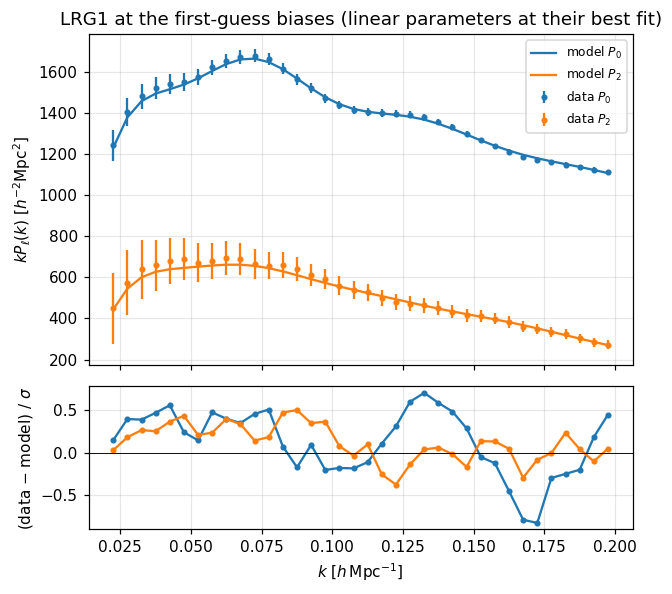

In [11]:
def best_fit_model(model, point):
    lk = model.likelihood[f'DESI_RSD_{TRACER}']
    model.logposterior(point)
    m = lk.get_best_fit()
    thetas = {name: lk.linear_param_means[name] + d for name, d in zip(lk.linear_param_dict, lk.bf_thetas)}
    chi2 = (lk.dd - m) @ lk.cinv @ (lk.dd - m)
    return m.reshape(2, -1), thetas, chi2

def plot_fit(m, title):
    fig, (ax, axr) = plt.subplots(2, 1, figsize=(6, 5.5), sharex=True, gridspec_kw={'height_ratios': [3, 1.3]})
    for i, (ell, col) in enumerate([(0, 'C0'), (2, 'C1')]):
        ax.errorbar(kdat, kdat * data[i], kdat * err[i], fmt='o', ms=3, color=col, label=rf'data $P_{ell}$')
        ax.plot(kdat, kdat * m[i], color=col, label=rf'model $P_{ell}$')
        axr.plot(kdat, (data[i] - m[i]) / err[i], 'o-', ms=3, color=col)
    axr.axhline(0, color='k', lw=0.6)
    ax.set(ylabel=r'$k P_\ell(k)\ [h^{-2}\mathrm{Mpc}^2]$', title=title)
    axr.set(xlabel=r'$k\ [h\,\mathrm{Mpc}^{-1}]$', ylabel=r'(data $-$ model) / $\sigma$')
    ax.legend(fontsize=8)
    plt.tight_layout()

m, thetas, chi2 = best_fit_model(model, point)
print('best-fit linear parameters at this point:', {k_: round(float(v), 3) for k_, v in thetas.items()})
print(f'chi2 = {chi2:.1f} for {data.size} data points')
plot_fit(m, f'{TRACER} at the first-guess biases (linear parameters at their best fit)')

By eye this already looks reasonable, because the linear parameters (counterterms, shot noise) have been optimized for
this point and absorb part of the error in $b_1$. Note how they've been pulled away from zero to do it.

**Reading the $\chi^2$.** The data are the mean of 25 mocks, but the covariance is that of one mock, so the real noise
in the data is 25 times smaller in variance than the covariance says. A good fit therefore has
$\chi^2 \approx N_\mathrm{data}/25 \approx 3$, not $\approx 72$. By that standard, $\chi^2 \approx 5$ is not a good fit;
you can see the systematic trend in the residuals.

## 4. Fitting the bias parameters at fixed cosmology

To find the best-fitting biases, run cobaya's `minimize` sampler on the same model, with `optimize: True` so the
likelihood is profiled (not marginalized) over the linear parameters (see the table in 3.3). It uses BOBYQA, a
derivative-free optimizer, starting from the `ref` distributions and minimizing $-\ln(\text{posterior})$.
With three free parameters it takes well under a minute.

In [12]:
from cobaya.run import run

info_min = make_info(optimize=True)
info_min['sampler'] = {'minimize': {'method': 'bobyqa', 'override_bobyqa': {'rhoend': 0.01}}}

t0 = time.time()
updated_info, minimizer = run(info_min, force=True)   # no 'output' key: results stay in memory
best = minimizer.products()['minimum']
print(f'minimizer took {time.time() - t0:.0f} s')
print(f"-log(posterior) at the minimum: {best['minuslogpost']:.3f}")
for p in [f'bsig8_{TRACER}', f'b2sig8_{TRACER}', f'bssig8_{TRACER}']:
    print(f'  {p:14s} = {best[p]: .4f}')

pk_theory_zs zfids from mock_abacus_cutsky_altmtl_phase_mean_qso_with_redshift_errors.h5: {'LRG1': 0.5}
zfids from mock_abacus_cutsky_altmtl_phase_mean_qso_with_redshift_errors.h5: {'LRG1': 0.5}
Loaded data!
Adding auw_LRG1 ~ N(0.0, 0.3)
[minimize] Initializing


[minimize] Run 1/2 will start from random initial point:


[minimize] {'bsig8_LRG1': np.float64(1.8669032675632011), 'b2sig8_LRG1': np.float64(0.24392742082535973), 'bssig8_LRG1': np.float64(0.07318093537397631)}


[minimize] Run 2/2 will start from random initial point:


[minimize] {'bsig8_LRG1': np.float64(2.008799854740164), 'b2sig8_LRG1': np.float64(-0.3768180321249849), 'bssig8_LRG1': np.float64(-0.5378376996286983)}


[prior] *WARNING* There are unbounded parameters (['b2sig8_LRG1', 'bssig8_LRG1']). Prior bounds are given at 0.9999995 confidence level. Beware of likelihood modes at the edge of the prior


... (5 outputs left out)

[minimize] -log(posterior) minimized to 8.79425


[minimize] Parameter values at minimum:
   weight  minuslogpost  bsig8_LRG1  b2sig8_LRG1  bssig8_LRG1    sigma8    omegam  minuslogprior  minuslogprior__0      chi2  chi2__DESI_RSD_LRG1
0     1.0       8.79425    1.822149    -0.542655    -0.758056  0.807673  0.315192       7.512104          7.512104  2.564292             2.564292


[minimize] Full set of minima:
{'0': (8.794249729914004, True), '1': (8.794266161852198, True)}


minimizer took 6 s
-log(posterior) at the minimum: 8.794
  bsig8_LRG1     =  1.8221
  b2sig8_LRG1    = -0.5427
  bssig8_LRG1    = -0.7581


The best-fit biases in the sampled basis convert back to the Lagrangian $b$'s of section 1 through the `zPars`
of the theory: $b_1 = \texttt{bsig8}\,/\,[(\sigma_8(z)/\sigma_8^\mathrm{fid}(z))\sqrt{A_\mathrm{AP}}] - 1$, and
similarly for $b_2$ and $b_s$. At the true cosmology both factors are within a fraction of a percent of 1, because
the fiducial cosmology is almost the truth.
Finally, compare the fit with the data:

[model] *WARNING* Ignored blocks/options: ['sampler']


pk_theory_zs zfids from mock_abacus_cutsky_altmtl_phase_mean_qso_with_redshift_errors.h5: {'LRG1': 0.5}


zfids from mock_abacus_cutsky_altmtl_phase_mean_qso_with_redshift_errors.h5: {'LRG1': 0.5}
Loaded data!
Adding auw_LRG1 ~ N(0.0, 0.3)


sigma8(z)/sigma8_fid(z) = 1.0002, f(z) = 0.7590, qpar = 1.0000, qperp = 1.0000
Lagrangian biases: b1 = 0.822, b2 = -0.542, bs = -0.758
best-fit linear parameters: {'alpha0_LRG1': 0.71, 'alpha2_LRG1': -0.443, 'SN0_LRG1': -200.387, 'SN2_LRG1': -12666.961, 'auw_LRG1': -0.001}
chi2 = 2.5 for 72 data points; expect about 2.9 for a good fit to a 25-mock mean


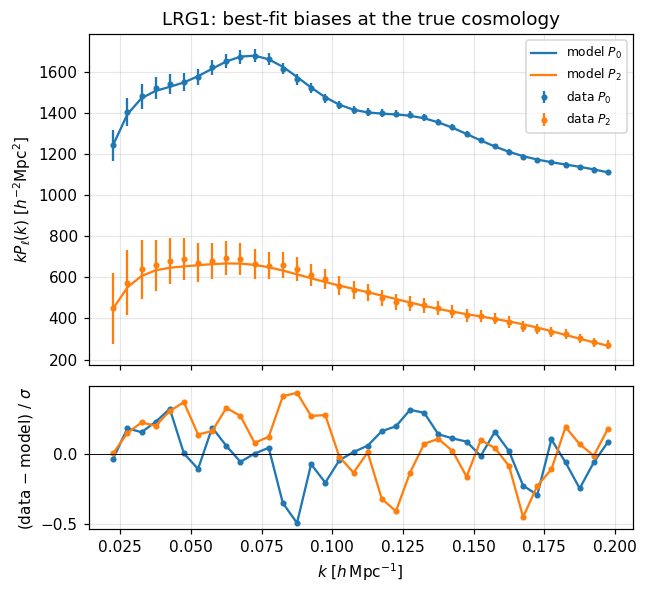

In [13]:
model_opt = get_model(info_min)
best_point = {p: best[p] for p in model_opt.parameterization.sampled_params()}
m, thetas, chi2 = best_fit_model(model_opt, best_point)
zp = model_opt.provider.get_result('zPars')['%.2f' % zeffs[0]]     # sigma8(z)/sigma8_fid(z), f, qpar, qperp
scale = zp[0] * np.sqrt(1 / (zp[2] * zp[3]**2))
print(f'sigma8(z)/sigma8_fid(z) = {zp[0]:.4f}, f(z) = {zp[1]:.4f}, qpar = {zp[2]:.4f}, qperp = {zp[3]:.4f}')
print(f'Lagrangian biases: b1 = {best[f"bsig8_{TRACER}"] / scale - 1:.3f}, '
      f'b2 = {best[f"b2sig8_{TRACER}"] / (zp[0] * scale):.3f}, bs = {best[f"bssig8_{TRACER}"] / (zp[0] * scale):.3f}')
print('best-fit linear parameters:', {k_: round(float(v), 3) for k_, v in thetas.items()})
print(f'chi2 = {chi2:.1f} for {data.size} data points; expect about {data.size / 25:.1f} for a good fit to a 25-mock mean')
plot_fit(m, f'{TRACER}: best-fit biases at the true cosmology')

The fit is now as good as the noise in the data allows, with $\chi^2 \approx N_\mathrm{data}/25$ and no trend in the residuals.
Two more things to notice:

* the AUW amplitude comes out at zero, as it should: these data already include the angular upweighting, so the
  template has nothing to correct;
* the $-\ln(\text{posterior})$ printed by the minimizer is not comparable with the log-posterior of section 3.5,
  because `optimize: True` removes the $\ln\det L$ term. Compare $\chi^2$ values instead.

## 5. Where to go next

* **Other tracers.** The package also holds `BGS`, `LRG2`, `LRG3`, `ELG` and `QSO`. Change `TRACER` and write a
  `configs/params_linear_<TRACER>.yaml` (the shot-noise prior widths scale with $1/\bar n$ of the tracer). For QSO,
  free `a2_QSO` (e.g. a flat prior on $[0, 100]$) to absorb redshift-error damping, and use `Rsmooth` only if you add BAO.
* **Freeing cosmology.** Replace a fixed value in `params` by a prior, e.g.
  `'H0': {'prior': {'min': 55, 'max': 79}, 'ref': {'dist': 'norm', 'loc': 67.36, 'scale': 1}}`.
  `configs/fit_LRG1_abacus_cutsky.yaml` is a complete MCMC configuration with the baseline priors; run it with
  `cobaya-run configs/fit_LRG1_abacus_cutsky.yaml` from the repo root.
* **The model alone.** Section 1 runs without the data package: `compute_pkxi_emu` plus the monomial contraction is
  enough to make predictions for any cosmology inside the emulator's training range.